In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ca = pd.read_csv('cust_activity.csv')
cb = pd.read_csv('cust_bio.csv')
cs = pd.read_csv('cust_sub.csv')
orders = pd.read_csv('orders (1).csv')
sp = pd.read_csv('sp.csv')

In [3]:
print(ca.shape)
print(cb.shape)
print(cs.shape)
print(orders.shape)
print(sp.shape)

(7500, 3)
(478, 3)
(51, 3)
(127, 4)
(6, 5)


In [4]:
print(ca.columns)
print(cb.columns)
print(cs.columns)
print(orders.columns)
print(sp.columns)

Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Cust_ID', 'City', 'Age'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')
Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')


In [5]:
 ca.isnull().sum()
 cb.isnull().sum()
 cs.isnull().sum()
 orders.isnull().sum()
 sp.isnull().sum()

Plan_Var_ID    0
Plan_ID        0
Plan_name      0
Price          0
Duration       0
dtype: int64

In [6]:
for i in [ca,cb,cs,orders,sp]:
    print(i.isnull().sum())

Cust_ID     0
Activity    0
Date        0
dtype: int64
Cust_ID    0
City       0
Age        0
dtype: int64
Cust_ID          0
Plan_Var_ID      0
Purchase_Date    0
dtype: int64
Order_id        0
Cust_ID         0
Amount          0
Payment_mode    0
dtype: int64
Plan_Var_ID    0
Plan_ID        0
Plan_name      0
Price          0
Duration       0
dtype: int64


In [7]:
def check_dup(data):
    dup = data.duplicated().sum()
    if dup > 0:
        print(dup)
    else:
        print('No Duplicates')

In [8]:
for i in [ca,cb,cs,orders,sp]:
    check_dup(i)

No Duplicates
No Duplicates
No Duplicates
No Duplicates
No Duplicates


In [69]:
####!pip install plotly

In [9]:
import plotly.express as px

In [10]:
q2 = cb['City'].value_counts().reset_index()
q2

,City,count
0,Chennai,109
1,Delhi,106
2,Kolkata,94
3,Noida,92
4,Mumbai,77


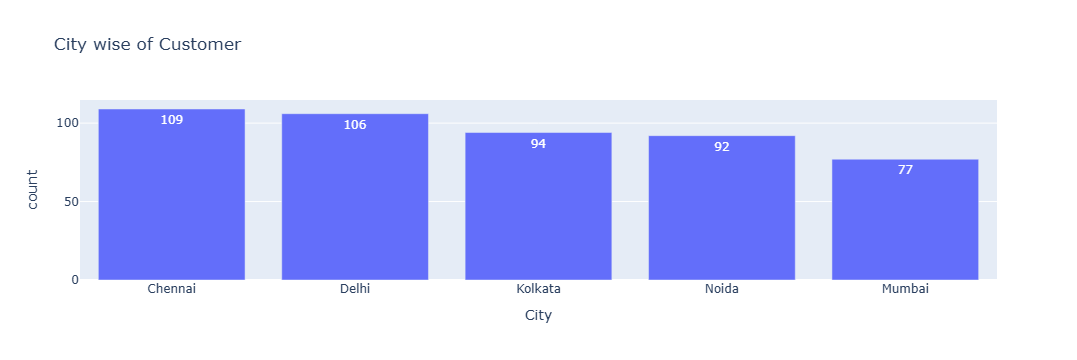

In [11]:
fig = px.bar(data_frame = q2, x = 'City', y = 'count', title = 'City wise of Customer',
            text = 'count')
fig.show()

In [12]:
cb['Age'].describe()

count    478.000000
mean      28.740586
std        5.376756
min       20.000000
25%       24.000000
50%       29.000000
75%       34.000000
max       37.000000
Name: Age, dtype: float64

In [13]:
cb['Age_Range'] = pd.cut(cb['Age'], bins = [19,24,29,34,39])
cb['Age_Range'] = cb['Age_Range'].astype(str)

In [14]:
q3 = cb['Age_Range'].value_counts().reset_index()
q3

,Age_Range,count
0,"(19, 24]",137
1,"(29, 34]",130
2,"(24, 29]",120
3,"(34, 39]",91


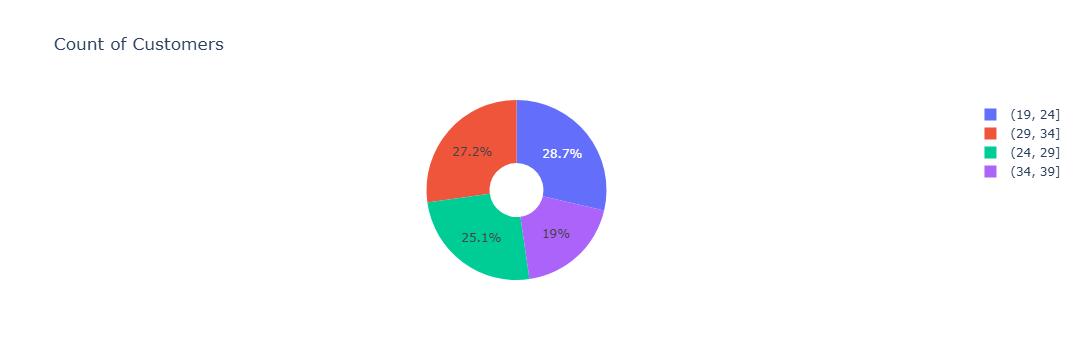

In [15]:
fig = px.pie(data_frame = q3, names = 'Age_Range', values = 'count', title = 'Count of Customers', hole = 0.3)
fig.show()

In [16]:
q4 = ca['Activity'].value_counts().reset_index()
q4

,Activity,count
0,Browse,6548
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


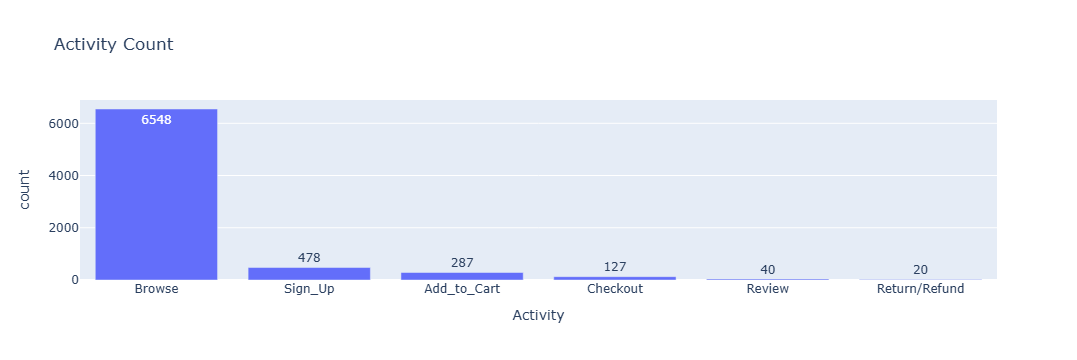

In [17]:
fig = px.bar(data_frame = q4, x = 'Activity', y = 'count', title = 'Activity Count', text = 'count')
fig.show()


In [18]:
print(ca.columns)
print(orders.columns)

Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')


In [19]:
ca['Date'] = pd.to_datetime(ca['Date'])
ca['Month'] = ca['Date'].dt.month

In [20]:
ca_checkout = ca[ca['Activity']=='Checkout']
print(ca_checkout.shape)
print(orders.shape)

(127, 4)
(127, 4)


In [21]:
ca_orders = pd.merge(orders, ca_checkout, on = 'Cust_ID', how = 'inner')
ca_orders.head()

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date,Month
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26,4
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01,2
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22,7
3,ORD_74,CUS_360,5736.31,COD,Checkout,2025-05-24,5
4,ORD_75,CUS_714,1592.53,Debit Card,Checkout,2024-06-19,6


In [22]:
q5 = ca_orders.groupby(['Month'])['Amount'].sum().reset_index()
q5

,Month,Amount
0,1,27022.20
1,2,70477.42
2,3,74777.59
3,4,88080.66
4,5,60200.46
5,6,69580.07
6,7,80416.05
7,8,27227.29
8,9,34804.62
9,10,30298.38


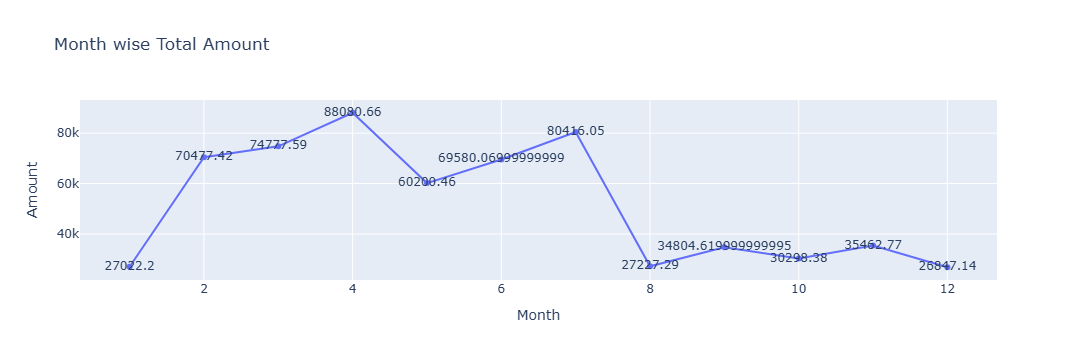

In [23]:
fig = px.line(data_frame=q5, x='Month', y='Amount', title='Month wise Total Amount',
              text='Amount')
fig.show()

5 question

In [24]:
cs_sp = pd.merge(cs,sp,on='Plan_Var_ID', how = 'inner')
cs_sp.head()

,Cust_ID,Plan_Var_ID,Purchase_Date,Plan_ID,Plan_name,Price,Duration
0,CUS_626,P1_1Y,2025-05-15,P1,Silver,1200.0,1 Year
1,CUS_723,P1_1Y,2024-07-23,P1,Silver,1200.0,1 Year
2,CUS_575,P1_1Y,2024-11-14,P1,Silver,1200.0,1 Year
3,CUS_232,P2_6M,2025-04-19,P2,Gold,1440.0,6 Months
4,CUS_346,P2_1Y,2024-01-31,P2,Gold,2400.0,1 Year


In [25]:
q6 = cs_sp.groupby(['Plan_Var_ID'])['Price'].sum().reset_index()
q6

,Plan_Var_ID,Price
0,P1_1Y,16800.0
1,P1_6M,5040.0
2,P2_1Y,24000.0
3,P2_6M,7200.0
4,P3_1Y,28800.0
5,P3_6M,25920.0


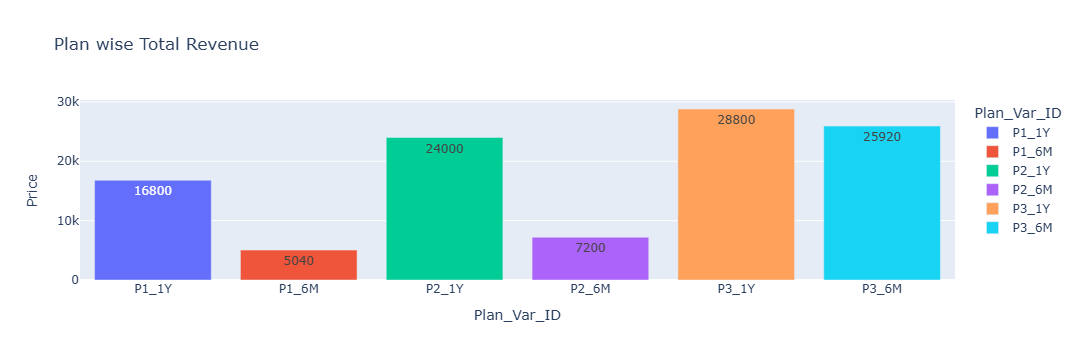

In [26]:
fig = px.bar(data_frame=q6, x='Plan_Var_ID', y='Price',
             title='Plan wise Total Revenue', color = 'Plan_Var_ID',
             text = 'Price')
fig.show()

Funnel Analysis

In [27]:
w1 = ca.groupby(['Cust_ID','Activity'])['Activity'].count().reset_index(name='Count')
w1.head()  

,Cust_ID,Activity,Count
0,CUS_121,Add_to_Cart,1
1,CUS_121,Browse,8
2,CUS_121,Checkout,1
3,CUS_121,Sign_Up,1
4,CUS_122,Browse,10


In [28]:
funnel = w1['Activity'].value_counts().reset_index()
funnel

,Activity,count
0,Browse,681
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


In [29]:
funnel['Prev_Count'] = np.where(funnel['Activity'] == 'Return/Refund',
                                funnel['count'].shift(2),
                                funnel['count'].shift(1))
funnel                                

,Activity,count,Prev_Count
0,Browse,681,NaN
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,127.0


In [30]:
funnel['Per_Conversion'] = round((funnel['count']/funnel['Prev_Count'])*100,2)
funnel.fillna(0, inplace = True)
funnel

,Activity,count,Prev_Count,Per_Conversion
0,Browse,681,0.0,0.00
1,Sign_Up,478,681.0,70.19
2,Add_to_Cart,287,478.0,60.04
3,Checkout,127,287.0,44.25
4,Review,40,127.0,31.50
5,Return/Refund,20,127.0,15.75


In [31]:
funnel['Per_Conversion'] = funnel['Per_Conversion'].apply(lambda x : str(x) + '%')
funnel

,Activity,count,Prev_Count,Per_Conversion
0,Browse,681,0.0,0.0%
1,Sign_Up,478,681.0,70.19%
2,Add_to_Cart,287,478.0,60.04%
3,Checkout,127,287.0,44.25%
4,Review,40,127.0,31.5%
5,Return/Refund,20,127.0,15.75%


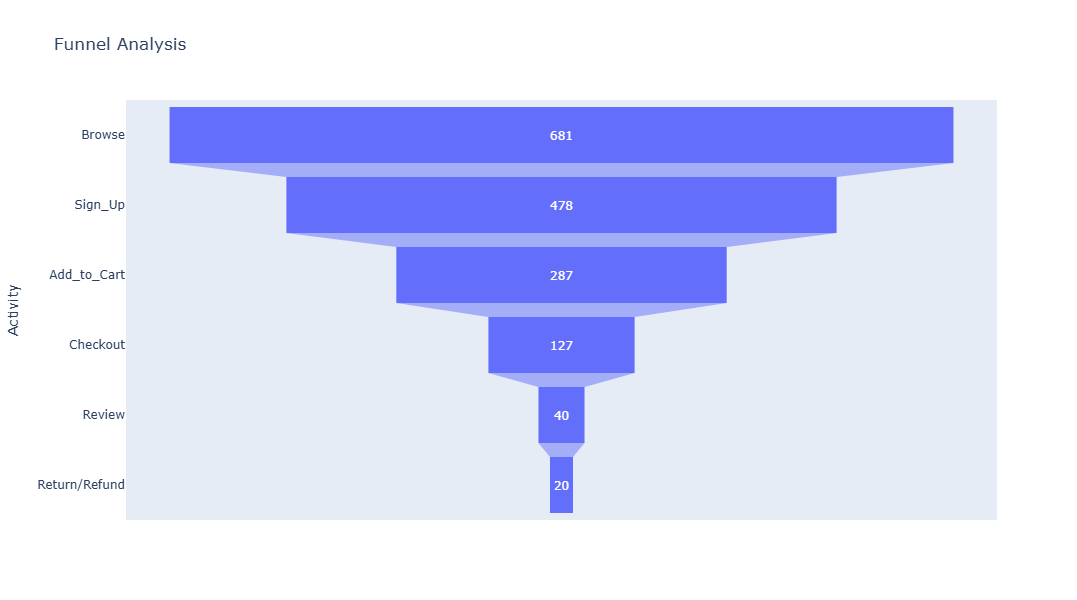

In [32]:
fig = px.funnel(data_frame=funnel, y='Activity', x='count'
                ,title='Funnel Analysis', height=600,hover_data='Per_Conversion')
fig.show()

Question 7

In [33]:
ca['Date'] = pd.to_datetime(ca['Date'])

In [34]:
pt1 = pd.pivot_table(data=ca,index=['Cust_ID'], columns=['Activity'],
                     values='Date', aggfunc='min')
pt1.head(15)


Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up
Cust_ID,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21


In [35]:
pt1['DD_Browse_2_Signup'] = (pt1['Sign_Up'] - pt1['Browse']).dt.days
pt1['DD_Signup_2_Add2Cart'] =(pt1['Add_to_Cart'] - pt1['Sign_Up']).dt.days
pt1['DD_Add2Cart_2_Checkout'] = (pt1['Checkout'] - pt1['Add_to_Cart']).dt.days
pt1['DD_Checkout_2_Review'] = (pt1['Review'] - pt1['Checkout']).dt.days
pt1['DD_Checkout_2_Return/Refund'] = (pt1['Return/Refund'] - pt1['Checkout']).dt.days
pt1.head()

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,DD_Browse_2_Signup,DD_Signup_2_Add2Cart,DD_Add2Cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Return/Refund
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,-3.0,3.0,8.0,NaN,NaN
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05,-1.0,1.0,NaN,NaN,NaN
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15,-2.0,NaN,NaN,NaN,NaN


In [36]:
pt2 = pt1.iloc[:,-5:]
pt2.head(2)

Activity,DD_Browse_2_Signup,DD_Signup_2_Add2Cart,DD_Add2Cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Return/Refund
Cust_ID,,,,,
CUS_121,-3.0,3.0,8.0,NaN,NaN
CUS_122,NaN,NaN,NaN,NaN,NaN


In [39]:
pt2.mean()

Activity
DD_Browse_2_Signup             -1.550209
DD_Signup_2_Add2Cart            2.512195
DD_Add2Cart_2_Checkout         14.425197
DD_Checkout_2_Review            2.625000
DD_Checkout_2_Return/Refund     3.400000
dtype: float64

In [45]:
tran_days = pt2.mean()
tran_days

Activity
DD_Browse_2_Signup             -1.550209
DD_Signup_2_Add2Cart            2.512195
DD_Add2Cart_2_Checkout         14.425197
DD_Checkout_2_Review            2.625000
DD_Checkout_2_Return/Refund     3.400000
dtype: float64

In [46]:
avg_days_to_tran = [0] + list(tran_days.values)
print(avg_days_to_tran)

[0, np.float64(-1.5502092050209204), np.float64(2.5121951219512195), np.float64(14.4251968503937), np.float64(2.625), np.float64(3.4)]


In [47]:
funnel['Avg_Days_2Tran'] = avg_days_to_tran
funnel['Avg_Days_2Tran'] = funnel['Avg_Days_2Tran'].apply(lambda x : round(x,2))
funnel

,Activity,count,Prev_Count,Per_Conversion,Avg_Days_2Tran
0,Browse,681,0.0,0.0%,0.00
1,Sign_Up,478,681.0,70.19%,-1.55
2,Add_to_Cart,287,478.0,60.04%,2.51
3,Checkout,127,287.0,44.25%,14.43
4,Review,40,127.0,31.5%,2.62
5,Return/Refund,20,127.0,15.75%,3.40


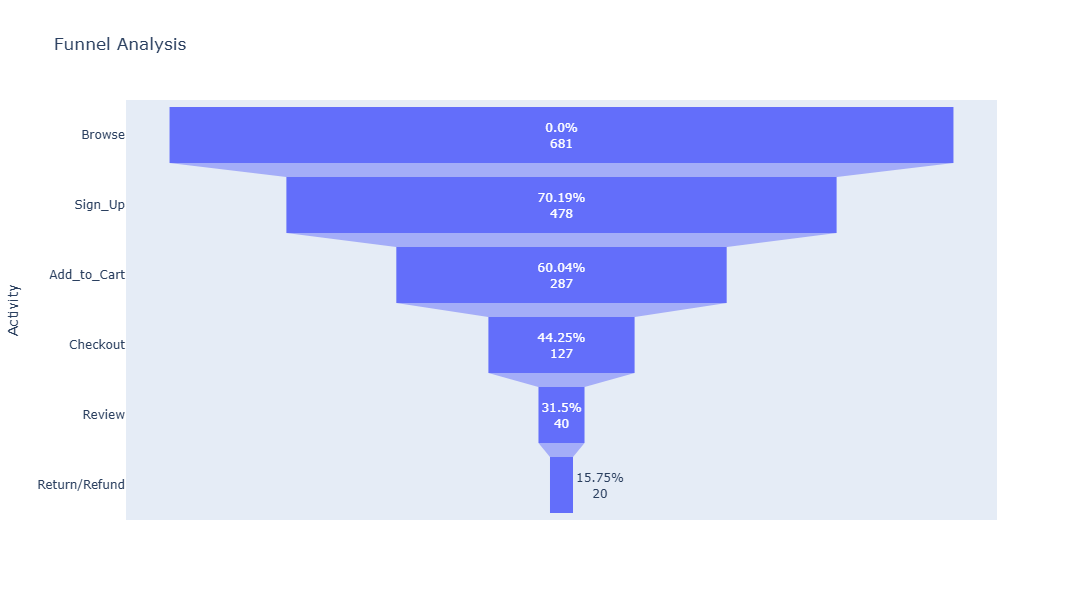

In [55]:
fig = px.funnel(data_frame=funnel, x='count', y='Activity', text = 'Per_Conversion'
                ,title='Funnel Analysis', height=600,hover_data='Avg_Days_2Tran')
fig.show()

city wise funnel

In [56]:
def city_wise_funnel(city_name):
    city_df = cb[cb['city']==city_name]

In [58]:
demo = pd.DataFrame({'City' : ['Delhi']*5 + ['Noida']*5 + ['Pune']*5,
                     'Sales' : [5000,6000,6000,7500,9000,3500,4200,5400,8700,8700,
                                11500,14500,18000,18000,18000],
                     'Year' : [2015,2016,2017,2018,2019]*3})
demo

,City,Sales,Year
0,Delhi,5000,2015
1,Delhi,6000,2016
2,Delhi,6000,2017
3,Delhi,7500,2018
4,Delhi,9000,2019
5,Noida,3500,2015
6,Noida,4200,2016
7,Noida,5400,2017
8,Noida,8700,2018
9,Noida,8700,2019


In [59]:
demo1 = demo.copy()

In [60]:
noida = demo.query("City=='Noida'")
noida

,City,Sales,Year
5,Noida,3500,2015
6,Noida,4200,2016
7,Noida,5400,2017
8,Noida,8700,2018
9,Noida,8700,2019


In [63]:
import warnings
warnings.filterwarnings('ignore')

In [62]:
noida['Rank_min'] = noida['Sales'].rank(ascending=False, method='min')
noida['Rank_max'] = noida['Sales'].rank(ascending=False, method='max')
noida['Rank_avg'] = noida['Sales'].rank(ascending=False, method='average')
noida['Rank_first'] = noida['Sales'].rank(ascending=False, method='first')
noida['Rank_dense'] = noida['Sales'].rank(ascending=False, method='dense')
noida

,City,Sales,Year,Rank_min,Rank_max,Rank_avg,Rank_first,Rank_dense
5,Noida,3500,2015,5.0,5.0,5.0,5.0,4.0
6,Noida,4200,2016,4.0,4.0,4.0,4.0,3.0
7,Noida,5400,2017,3.0,3.0,3.0,3.0,2.0
8,Noida,8700,2018,1.0,2.0,1.5,1.0,1.0
9,Noida,8700,2019,1.0,2.0,1.5,2.0,1.0


In [64]:
demo2 = demo1.copy()

In [65]:
demo1['Rank'] = demo1.groupby('City')['Sales'].rank(ascending=False,method='dense')
demo1

,City,Sales,Year,Rank
0,Delhi,5000,2015,4.0
1,Delhi,6000,2016,3.0
2,Delhi,6000,2017,3.0
3,Delhi,7500,2018,2.0
4,Delhi,9000,2019,1.0
5,Noida,3500,2015,4.0
6,Noida,4200,2016,3.0
7,Noida,5400,2017,2.0
8,Noida,8700,2018,1.0
9,Noida,8700,2019,1.0


In [66]:
top3 = demo1[demo1['Rank']<=3]
top3

,City,Sales,Year,Rank
1,Delhi,6000,2016,3.0
2,Delhi,6000,2017,3.0
3,Delhi,7500,2018,2.0
4,Delhi,9000,2019,1.0
6,Noida,4200,2016,3.0
7,Noida,5400,2017,2.0
8,Noida,8700,2018,1.0
9,Noida,8700,2019,1.0
10,Pune,11500,2015,3.0
11,Pune,14500,2016,2.0


In [68]:
demo2.head(4)

,City,Sales,Year
0,Delhi,5000,2015
1,Delhi,6000,2016
2,Delhi,6000,2017
3,Delhi,7500,2018
